In [2]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train = pd.read_csv("student_dataset.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")

X = train.drop(columns=["condition", "unit_id"])
y = train["condition"]

categorical_columns = X.select_dtypes(include="object").columns.tolist()
numeric_columns = X.select_dtypes(exclude="object").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
            ),
            numeric_columns,
        ),
        (
            "categorical",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore"),
            ),
            categorical_columns,
        ),
    ]
)

models = {
    "Most common class": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        preprocessor,
        LogisticRegression(max_iter=2000, random_state=42),
    ),
    "Random forest": make_pipeline(
        preprocessor,
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        ),
    ),
    "Extra trees": make_pipeline(
        preprocessor,
        ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        ),
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
        },
        n_jobs=1,
    )

    accuracy = scores["test_accuracy"]
    balanced_accuracy = scores["test_balanced_accuracy"]

    print(f"\n{name}")
    print("Accuracy by fold:", [round(s, 4) for s in accuracy])
    print(f"Mean accuracy: {accuracy.mean():.4f} ± {accuracy.std():.4f}")
    print(f"Mean balanced accuracy: {balanced_accuracy.mean():.4f}")


Most common class
Accuracy by fold: [np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5)]
Mean accuracy: 0.5000 ± 0.0000
Mean balanced accuracy: 0.3333

Logistic regression
Accuracy by fold: [np.float64(0.8275), np.float64(0.83), np.float64(0.8241), np.float64(0.8247), np.float64(0.8209)]
Mean accuracy: 0.8254 ± 0.0031
Mean balanced accuracy: 0.7988

Random forest
Accuracy by fold: [np.float64(0.8803), np.float64(0.8784), np.float64(0.885), np.float64(0.8738), np.float64(0.8784)]
Mean accuracy: 0.8792 ± 0.0036
Mean balanced accuracy: 0.8579

Extra trees
Accuracy by fold: [np.float64(0.8712), np.float64(0.8694), np.float64(0.8731), np.float64(0.87), np.float64(0.87)]
Mean accuracy: 0.8707 ± 0.0013
Mean balanced accuracy: 0.8422


In [3]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Load the files
train = pd.read_csv("student_dataset.csv")

target = "condition"
X = train.drop(columns=[target, "unit_id"])
y = train[target]

# Separate text categories and sensor measurements
categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_columns = X.select_dtypes(include=["number"]).columns.tolist()

# Fill missing values and encode the machine type
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_columns
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]),
            categorical_columns
        )
    ],
    remainder="drop"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
    n_jobs=-1
)

print("HistGradientBoosting")
print("Accuracy by fold:", np.round(scores["test_accuracy"], 4))
print(
    f"Mean accuracy: {scores['test_accuracy'].mean():.4f} "
    f"± {scores['test_accuracy'].std():.4f}"
)
print(f"Mean balanced accuracy: {scores['test_balanced_accuracy'].mean():.4f}")

HistGradientBoosting
Accuracy by fold: [0.8838 0.8825 0.8881 0.8853 0.8784]
Mean accuracy: 0.8836 ± 0.0032
Mean balanced accuracy: 0.8650


In [4]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

print("Confusion matrix (rows = actual class, columns = predicted class):")
print(confusion_matrix(y, oof_predictions, labels=[0, 1, 2]))

print("\nPer-class results:")
print(classification_report(
    y,
    oof_predictions,
    labels=[0, 1, 2],
    target_names=["Normal", "Thermal failure", "Mechanical failure"],
    digits=4
))

Confusion matrix (rows = actual class, columns = predicted class):
[[7516  254  230]
 [ 451 3322  227]
 [ 500  200 3300]]

Per-class results:
                    precision    recall  f1-score   support

            Normal     0.8877    0.9395    0.9129      8000
   Thermal failure     0.8798    0.8305    0.8544      4000
Mechanical failure     0.8784    0.8250    0.8508      4000

          accuracy                         0.8836     16000
         macro avg     0.8819    0.8650    0.8727     16000
      weighted avg     0.8834    0.8836    0.8827     16000



In [5]:
from sklearn.model_selection import RandomizedSearchCV

parameter_options = {
    "classifier__max_iter": [100, 200, 300, 400],
    "classifier__learning_rate": [0.03, 0.05, 0.08, 0.12],
    "classifier__max_leaf_nodes": [15, 31, 45, 63],
    "classifier__min_samples_leaf": [10, 20, 30, 50],
    "classifier__l2_regularization": [0.0, 0.1, 1.0, 5.0],
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=parameter_options,
    n_iter=16,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X, y)

print("Best cross-validation accuracy:", round(search.best_score_, 4))
print("Best settings:")
print(search.best_params_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best cross-validation accuracy: 0.8841
Best settings:
{'classifier__min_samples_leaf': 30, 'classifier__max_leaf_nodes': 31, 'classifier__max_iter': 100, 'classifier__learning_rate': 0.05, 'classifier__l2_regularization': 0.0}


In [6]:
import pandas as pd

train = pd.read_csv("student_dataset.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")

target = "condition"
id_column = "unit_id"

# Keep the template's row order and identifiers
X_train = train.drop(columns=[target, id_column])
y_train = train[target]
X_test = test.drop(columns=[id_column])

# Refit the selected model on all available labeled rows
final_model = search.best_estimator_
final_model.fit(X_train, y_train)

predictions = final_model.predict(X_test).astype(int)

submission = pd.DataFrame({
    id_column: sample[id_column],
    target: predictions
})

# Check that predictions correspond to the test IDs in the same order
assert len(submission) == len(test) == len(sample)
assert submission[id_column].equals(test[id_column])
assert submission[id_column].equals(sample[id_column])
assert submission[target].isin([0, 1, 2]).all()
assert submission[target].notna().all()

output_path = "submission_machine_condition.csv"
submission.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows and columns:", submission.shape)
print("Predicted class counts:")
print(submission[target].value_counts().sort_index())
print("\nFirst five rows:")
print(submission.head())

Saved: submission_machine_condition.csv
Rows and columns: (4000, 2)
Predicted class counts:
condition
0    2123
1     941
2     936
Name: count, dtype: int64

First five rows:
      unit_id  condition
0  UNT-184630          0
1  UNT-228473          0
2  UNT-255783          1
3  UNT-119059          2
4  UNT-205559          0


In [7]:
%pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.6 MB/s eta 0:00:00


In [10]:
import numpy as np

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_accuracies = []
fold_balanced_accuracies = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_cat, y_cat), start=1):
    X_fold_train = X_cat.iloc[train_idx]
    X_fold_valid = X_cat.iloc[valid_idx]
    y_fold_train = y_cat.iloc[train_idx]
    y_fold_valid = y_cat.iloc[valid_idx]

    fold_model = CatBoostClassifier(
        iterations=800,
        depth=7,
        learning_rate=0.05,
        loss_function="MultiClass",
        cat_features=categorical_columns,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    fold_model.fit(X_fold_train, y_fold_train)
    fold_predictions = fold_model.predict(X_fold_valid).ravel()

    fold_accuracy = accuracy_score(y_fold_valid, fold_predictions)
    fold_balanced_accuracy = balanced_accuracy_score(
        y_fold_valid, fold_predictions
    )

    fold_accuracies.append(fold_accuracy)
    fold_balanced_accuracies.append(fold_balanced_accuracy)

    print(
        f"Fold {fold}: accuracy={fold_accuracy:.4f}, "
        f"balanced accuracy={fold_balanced_accuracy:.4f}"
    )

print("\nCatBoost")
print("Accuracy by fold:", np.round(fold_accuracies, 4))
print(
    f"Mean accuracy: {np.mean(fold_accuracies):.4f} "
    f"± {np.std(fold_accuracies):.4f}"
)
print(
    "Mean balanced accuracy:",
    round(np.mean(fold_balanced_accuracies), 4)
)

Fold 1: accuracy=0.8834, balanced accuracy=0.8662
Fold 2: accuracy=0.8847, balanced accuracy=0.8662
Fold 3: accuracy=0.8878, balanced accuracy=0.8702
Fold 4: accuracy=0.8844, balanced accuracy=0.8656
Fold 5: accuracy=0.8844, balanced accuracy=0.8635

CatBoost
Accuracy by fold: [0.8834 0.8847 0.8878 0.8844 0.8844]
Mean accuracy: 0.8849 ± 0.0015
Mean balanced accuracy: 0.8664


In [11]:
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

train = pd.read_csv("student_dataset.csv")

y_blend = train["condition"]
X_hgb = train.drop(columns=["condition", "unit_id"]).copy()
X_cat_blend = X_hgb.copy()

categorical_columns = X_cat_blend.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:
    X_cat_blend[column] = (
        X_cat_blend[column].fillna("Missing").astype(str)
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
classes = np.array([0, 1, 2])

oof_catboost = np.zeros((len(train), len(classes)))
oof_histgb = np.zeros((len(train), len(classes)))

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_hgb, y_blend), start=1
):
    # CatBoost fold
    cat_model = CatBoostClassifier(
        iterations=800,
        depth=7,
        learning_rate=0.05,
        loss_function="MultiClass",
        cat_features=categorical_columns,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )
    cat_model.fit(
        X_cat_blend.iloc[train_idx],
        y_blend.iloc[train_idx]
    )
    oof_catboost[valid_idx] = cat_model.predict_proba(
        X_cat_blend.iloc[valid_idx]
    )

    # Tuned HistGradientBoosting fold
    hgb_model = search.best_estimator_
    hgb_model.fit(
        X_hgb.iloc[train_idx],
        y_blend.iloc[train_idx]
    )
    oof_histgb[valid_idx] = hgb_model.predict_proba(
        X_hgb.iloc[valid_idx]
    )

    print(f"Finished fold {fold}/5")

# Compare models and blends on the same out-of-fold rows
for cat_weight in [0.0, 0.25, 0.5, 0.75, 1.0]:
    blended_probabilities = (
        cat_weight * oof_catboost
        + (1 - cat_weight) * oof_histgb
    )
    blended_predictions = classes[blended_probabilities.argmax(axis=1)]
    accuracy = accuracy_score(y_blend, blended_predictions)

    print(
        f"CatBoost share={cat_weight:.2f}, "
        f"HistGradientBoosting share={1-cat_weight:.2f}, "
        f"OOF accuracy={accuracy:.4f}"
    )

Finished fold 1/5
Finished fold 2/5
Finished fold 3/5
Finished fold 4/5
Finished fold 5/5
CatBoost share=0.00, HistGradientBoosting share=1.00, OOF accuracy=0.8841
CatBoost share=0.25, HistGradientBoosting share=0.75, OOF accuracy=0.8858
CatBoost share=0.50, HistGradientBoosting share=0.50, OOF accuracy=0.8868
CatBoost share=0.75, HistGradientBoosting share=0.25, OOF accuracy=0.8864
CatBoost share=1.00, HistGradientBoosting share=0.00, OOF accuracy=0.8849


In [12]:
import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.base import clone

train = pd.read_csv("student_dataset.csv")
test = pd.read_csv("test.csv")
sample = pd.read_csv("sample_submission.csv")

target = "condition"
id_column = "unit_id"
classes = np.array([0, 1, 2])

# HistGradientBoosting uses the original feature values, including missing values.
X_train_hgb = train.drop(columns=[target, id_column]).copy()
y_train = train[target]
X_test_hgb = test.drop(columns=[id_column]).copy()

# CatBoost receives category columns explicitly, with missing categories filled.
X_train_cat = X_train_hgb.copy()
X_test_cat = X_test_hgb.copy()

categorical_columns = X_train_cat.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:
    X_train_cat[column] = (
        X_train_cat[column].fillna("Missing").astype(str)
    )
    X_test_cat[column] = (
        X_test_cat[column].fillna("Missing").astype(str)
    )

# Fit the tuned HistGradientBoosting model on all training rows.
hgb_final = clone(search.best_estimator_)
hgb_final.fit(X_train_hgb, y_train)
hgb_probabilities = hgb_final.predict_proba(X_test_hgb)

# Fit CatBoost on all training rows.
cat_final = CatBoostClassifier(
    iterations=800,
    depth=7,
    learning_rate=0.05,
    loss_function="MultiClass",
    cat_features=categorical_columns,
    random_seed=42,
    verbose=False,
    thread_count=-1
)
cat_final.fit(X_train_cat, y_train)
cat_probabilities = cat_final.predict_proba(X_test_cat)

# Confirm both probability columns correspond to classes 0, 1, and 2.
assert np.array_equal(hgb_final.classes_, classes)
assert np.array_equal(cat_final.classes_, classes)

# Average the two models' probabilities equally, then choose the most likely class.
blended_probabilities = 0.5 * hgb_probabilities + 0.5 * cat_probabilities
predictions = classes[blended_probabilities.argmax(axis=1)]

submission = pd.DataFrame({
    id_column: sample[id_column],
    target: predictions
})

assert len(submission) == len(test) == len(sample)
assert submission[id_column].equals(test[id_column])
assert submission[id_column].equals(sample[id_column])
assert submission[target].isin(classes).all()

output_path = "submission_catboost_histgb_blend.csv"
submission.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows and columns:", submission.shape)
print("Predicted class counts:")
print(submission[target].value_counts().sort_index())
print("\nFirst five rows:")
print(submission.head())

Saved: submission_catboost_histgb_blend.csv
Rows and columns: (4000, 2)
Predicted class counts:
condition
0    2127
1     939
2     934
Name: count, dtype: int64

First five rows:
      unit_id  condition
0  UNT-184630          0
1  UNT-228473          0
2  UNT-255783          1
3  UNT-119059          2
4  UNT-205559          0


In [13]:
import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

train = pd.read_csv("student_dataset.csv")

X_engineered = train.drop(columns=["condition", "unit_id"]).copy()
y_engineered = train["condition"]

# Add physically motivated features; missing sensor values remain missing.
X_engineered["temperature_difference"] = (
    X_engineered["process_temp"] - X_engineered["ambient_temp"]
)
X_engineered["torque_speed_product"] = (
    X_engineered["drive_torque"] * X_engineered["shaft_speed"]
)

categorical_columns = X_engineered.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:
    X_engineered[column] = (
        X_engineered[column].fillna("Missing").astype(str)
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_engineered, y_engineered), start=1
):
    model = CatBoostClassifier(
        iterations=800,
        depth=7,
        learning_rate=0.05,
        loss_function="MultiClass",
        cat_features=categorical_columns,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_engineered.iloc[train_idx],
        y_engineered.iloc[train_idx]
    )
    predictions = model.predict(
        X_engineered.iloc[valid_idx]
    ).ravel()

    score = accuracy_score(y_engineered.iloc[valid_idx], predictions)
    fold_accuracies.append(score)
    print(f"Fold {fold}: accuracy={score:.4f}")

print(
    f"\nEngineered CatBoost mean accuracy: "
    f"{np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}"
)

Fold 1: accuracy=0.8841
Fold 2: accuracy=0.8894
Fold 3: accuracy=0.8884
Fold 4: accuracy=0.8831
Fold 5: accuracy=0.8819

Engineered CatBoost mean accuracy: 0.8854 ± 0.0030


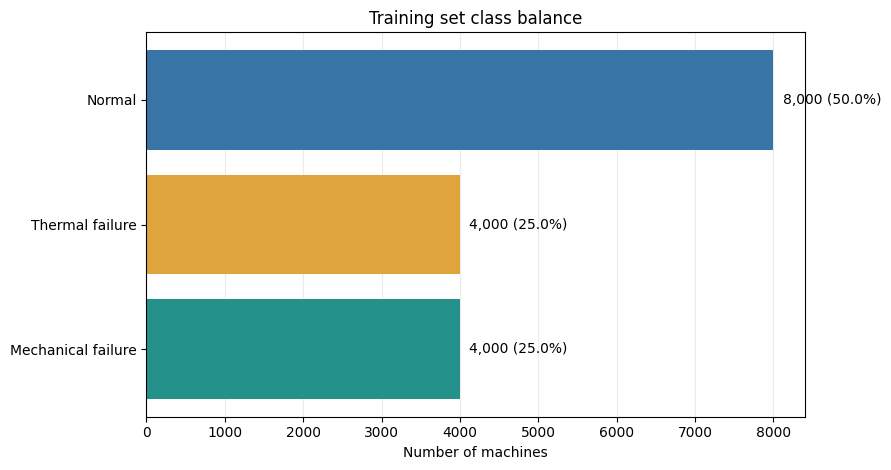

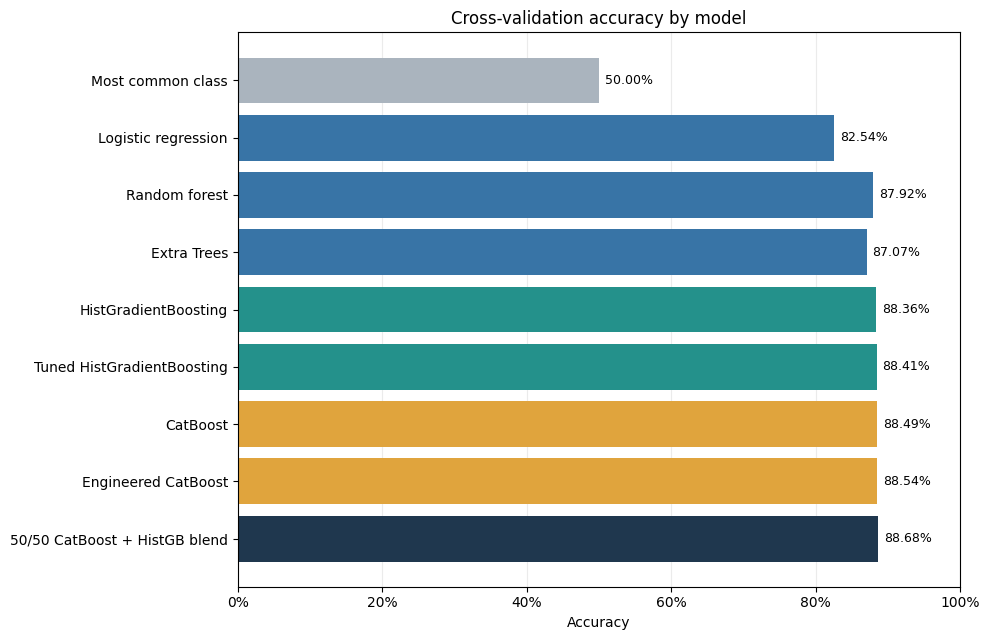

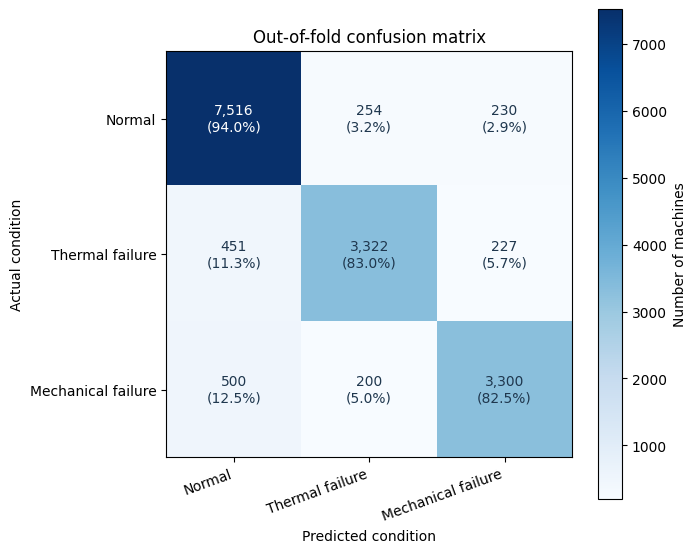

Saved the three figures in: /content/report_figures


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Reuse the training DataFrame if it is still in the notebook;
# otherwise load it from the notebook's current folder.
data = globals().get("train")
if not isinstance(data, pd.DataFrame) or "condition" not in data.columns:
    data = pd.read_csv("student_dataset.csv")

output_dir = Path("report_figures")
output_dir.mkdir(exist_ok=True)

class_names = ["Normal", "Thermal failure", "Mechanical failure"]
class_ids = [0, 1, 2]
colors = ["#3874A6", "#E0A43D", "#24918B"]

# Figure 1: class balance from the actual training data
counts = data["condition"].value_counts().reindex(class_ids, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(class_names, counts.values, color=colors)
ax.invert_yaxis()
ax.set_title("Training set class balance")
ax.set_xlabel("Number of machines")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_width() + max(counts.values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({count / len(data):.1%})",
        va="center"
    )

fig.tight_layout()
fig.savefig(output_dir / "figure_1_class_balance.png", dpi=220, bbox_inches="tight")
plt.show()


# Figure 2: validation accuracy from the results you shared
model_names = [
    "Most common class",
    "Logistic regression",
    "Random forest",
    "Extra Trees",
    "HistGradientBoosting",
    "Tuned HistGradientBoosting",
    "CatBoost",
    "Engineered CatBoost",
    "50/50 CatBoost + HistGB blend",
]
accuracies = [0.5000, 0.8254, 0.8792, 0.8707, 0.8836, 0.8841, 0.8849, 0.8854, 0.8868]
model_colors = [
    "#AAB4BE", "#3874A6", "#3874A6", "#3874A6",
    "#24918B", "#24918B", "#E0A43D", "#E0A43D", "#1F374E"
]

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(model_names, accuracies, color=model_colors)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("Cross-validation accuracy by model")
ax.set_xlabel("Accuracy")
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, score in zip(bars, accuracies):
    ax.text(
        score + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.2%}",
        va="center",
        fontsize=9
    )

fig.tight_layout()
fig.savefig(output_dir / "figure_2_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()


# Figure 3: the initial HistGradientBoosting out-of-fold confusion matrix
# This matches Figure 3 and its class metrics in the report.
cm = np.array([
    [7516, 254, 230],
    [451, 3322, 227],
    [500, 200, 3300]
])

row_percentages = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Out-of-fold confusion matrix")
ax.set_xlabel("Predicted condition")
ax.set_ylabel("Actual condition")
ax.set_xticks(class_ids, class_names, rotation=20, ha="right")
ax.set_yticks(class_ids, class_names)

threshold = cm.max() * 0.55
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        color = "white" if cm[row, col] > threshold else "#1F374E"
        ax.text(
            col, row,
            f"{cm[row, col]:,}\n({row_percentages[row, col]:.1%})",
            ha="center", va="center", color=color, fontsize=10
        )

fig.colorbar(image, ax=ax, label="Number of machines")
fig.tight_layout()
fig.savefig(output_dir / "figure_3_confusion_matrix.png", dpi=220, bbox_inches="tight")
plt.show()

print("Saved the three figures in:", output_dir.resolve())